In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ustawienie ziarna losowości dla powtarzalnych wyników
np.random.seed(42)

print("Biblioteki zaimportowane poprawnie!")

Biblioteki zaimportowane poprawnie!


In [2]:
# ==========================================
# ZADANIE 10 - SYMULACJA ZUŻYCIA ZASOBÓW
# ==========================================

# Pięć modeli Machine Learning
modele = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "SVM",
    "Neural Network"
]

# Parametry symulacji:
# (średni czas treningu, średnie CPU, średni RAM, średnia energia)
parametry = {
    "Linear Regression": (2, 20, 1.0, 0.01),
    "Decision Tree": (5, 35, 2.0, 0.03),
    "Random Forest": (15, 65, 4.0, 0.12),
    "SVM": (10, 50, 3.0, 0.07),
    "Neural Network": (30, 85, 6.0, 0.25)
}

dane = []

# Generujemy po 10 pomiarów dla każdego modelu
for model in modele:
    czas, cpu, ram, energia = parametry[model]

    for _ in range(10):
        dane.append({
            "model_name": model,
            "training_time_min": round(max(0.1, np.random.normal(czas, czas * 0.1)), 2),
            "cpu_percent": round(np.clip(np.random.normal(cpu, 5), 0, 100), 2),
            "ram_gb": round(max(0.1, np.random.normal(ram, ram * 0.1)), 2),
            "energy_kwh": round(max(0.001, np.random.normal(energia, energia * 0.1)), 4)
        })

# Tworzymy DataFrame
df = pd.DataFrame(dane)

# Wyświetlamy pierwsze 10 pomiarów
display(df.head(10))

# Sprawdzamy liczbę pomiarów
print("Liczba wszystkich pomiarów:", len(df))
print("\nLiczba pomiarów na model:")
print(df["model_name"].value_counts())

,model_name,training_time_min,cpu_percent,ram_gb,energy_kwh
0,Linear Regression,2.10,19.31,1.06,0.0115
1,Linear Regression,1.95,18.83,1.16,0.0108
2,Linear Regression,1.91,22.71,0.95,0.0095
3,Linear Regression,2.05,10.43,0.83,0.0094
4,Linear Regression,1.80,21.57,0.91,0.0086
5,Linear Regression,2.29,18.87,1.01,0.0086
6,Linear Regression,1.89,20.55,0.88,0.0104
7,Linear Regression,1.88,18.54,0.94,0.0119
8,Linear Regression,2.00,14.71,1.08,0.0088
9,Linear Regression,2.04,10.20,0.87,0.0102


Liczba wszystkich pomiarów: 50

Liczba pomiarów na model:
model_name
Linear Regression    10
Decision Tree        10
Random Forest        10
SVM                  10
Neural Network       10
Name: count, dtype: int64


In [3]:
# ==========================================
# ŚREDNIE ZUŻYCIE ZASOBÓW DLA KAŻDEGO MODELU
# ==========================================

# Grupujemy dane według nazwy modelu
# i obliczamy średnią dla każdej kolumny liczbowej
srednie = df.groupby("model_name")[
    ["training_time_min", "cpu_percent", "ram_gb", "energy_kwh"]
].mean()

# Zaokrąglamy wyniki
srednie = srednie.round(4)

print("ŚREDNIE ZUŻYCIE ZASOBÓW:")
display(srednie)

# Znajdujemy model o najniższym średnim zużyciu energii
najlepszy_model = srednie["energy_kwh"].idxmin()
najmniejsza_energia = srednie["energy_kwh"].min()

print(f"\nNajbardziej energooszczędny model: {najlepszy_model}")
print(f"Średnie zużycie energii: {najmniejsza_energia:.4f} kWh")

ŚREDNIE ZUŻYCIE ZASOBÓW:


,training_time_min,cpu_percent,ram_gb,energy_kwh
model_name,,,,
Decision Tree,4.941,34.889,1.957,0.0307
Linear Regression,1.991,17.572,0.969,0.0100
Neural Network,29.570,84.746,6.017,0.2608
Random Forest,14.513,65.755,4.106,0.1194
SVM,10.184,52.010,2.857,0.0683



Najbardziej energooszczędny model: Linear Regression
Średnie zużycie energii: 0.0100 kWh


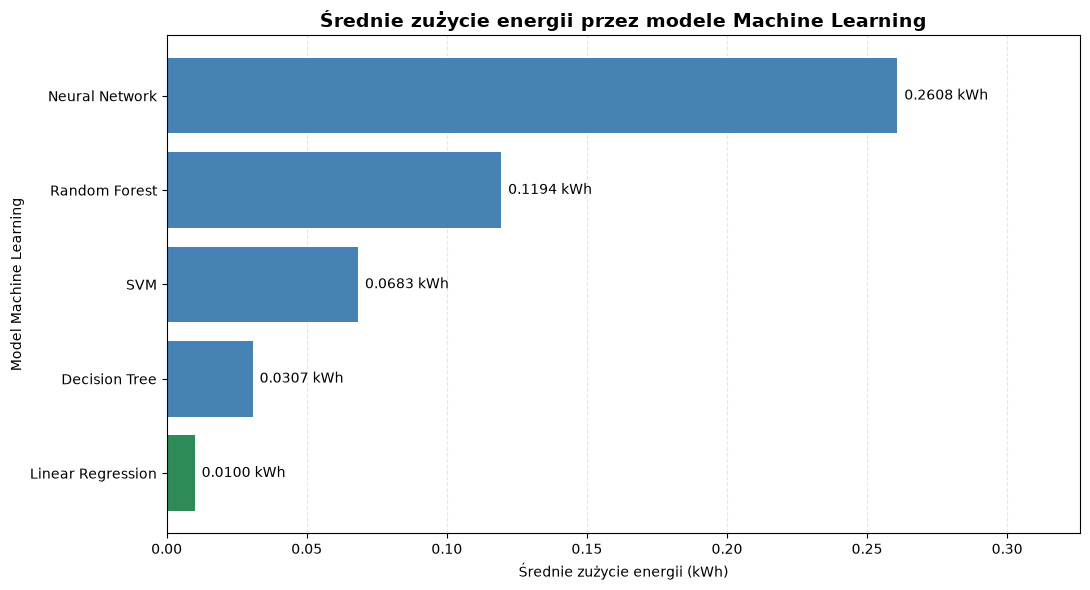

In [4]:
# ==========================================
# WYKRES ŚREDNIEGO ZUŻYCIA ENERGII
# ==========================================

# Sortujemy modele od najmniejszego zużycia energii
energia = srednie["energy_kwh"].sort_values()

# Wyróżniamy najbardziej energooszczędny model
kolory = [
    "seagreen" if model == najlepszy_model else "steelblue"
    for model in energia.index
]

# Tworzymy wykres
fig, ax = plt.subplots(figsize=(11, 6))

slupki = ax.barh(
    energia.index,
    energia.values,
    color=kolory
)

# Tytuł i opisy osi
ax.set_title(
    "Średnie zużycie energii przez modele Machine Learning",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Średnie zużycie energii (kWh)")
ax.set_ylabel("Model Machine Learning")

# Wartości przy słupkach
ax.bar_label(
    slupki,
    labels=[f"{x:.4f} kWh" for x in energia.values],
    padding=5
)

# Dodatkowe ustawienia
ax.set_xlim(0, energia.max() * 1.25)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Zapis wykresu
plt.savefig("zadanie10_energy_comparison.png", dpi=300)

# Wyświetlenie wykresu w notebooku
plt.show()

## Wnioski z analizy zużycia zasobów

Analiza obejmuje 50 symulowanych pomiarów zużycia zasobów przez pięć modeli Machine Learning, po 10 pomiarów dla każdego modelu.

### 1. Najbardziej energooszczędny model

Najniższe średnie zużycie energii uzyskał **Linear Regression — 0,0100 kWh**.

Kolejne modele pod względem rosnącego zużycia energii to:

1. Linear Regression — 0,0100 kWh
2. Decision Tree — 0,0307 kWh
3. SVM — 0,0683 kWh
4. Random Forest — 0,1194 kWh
5. Neural Network — 0,2608 kWh

### 2. Czas treningu

Najkrótszy średni czas treningu uzyskał Linear Regression (1,991 min), natomiast najdłuższy Neural Network (29,570 min).

### 3. Wykorzystanie CPU i RAM

Linear Regression charakteryzował się również najniższym średnim wykorzystaniem CPU (17,572%) oraz RAM (0,969 GB).

Neural Network osiągnął najwyższe średnie wykorzystanie CPU (84,746%) i RAM (6,017 GB).

### 4. Podsumowanie

W przeprowadzonej symulacji Linear Regression okazał się najbardziej energooszczędnym modelem, natomiast Neural Network zużywał najwięcej zasobów.

**Ograniczenie analizy:** dane zostały wygenerowane sztucznie, na podstawie przyjętych parametrów. Wyniki nie stanowią rzeczywistego porównania wydajności modeli. W praktyce zużycie energii zależy m.in. od sprzętu, wielkości zbioru danych, implementacji i konfiguracji modelu.